In [66]:
import pandas as pd
import matplotlib.pyplot as plt
import datetime as dt

In [67]:
dd=pd.read_csv('../dataset/dp_lms_student_analytics_dataset.csv')
dd.info()


<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   StudentID             500 non-null    int64
 1   StudentName           500 non-null    str  
 2   Gender                500 non-null    str  
 3   Age                   500 non-null    int64
 4   City                  500 non-null    str  
 5   Course                500 non-null    str  
 6   Instructor            500 non-null    str  
 7   EnrollmentDate        500 non-null    str  
 8   Batch                 500 non-null    str  
 9   CourseFee             500 non-null    int64
 10  PaymentMethod         500 non-null    str  
 11  AttendancePercentage  500 non-null    int64
 12  AssignmentScore       500 non-null    int64
 13  QuizScore             500 non-null    int64
 14  FinalScore            500 non-null    int64
 15  CourseProgress        500 non-null    int64
 16  StudyHoursPerWeek  

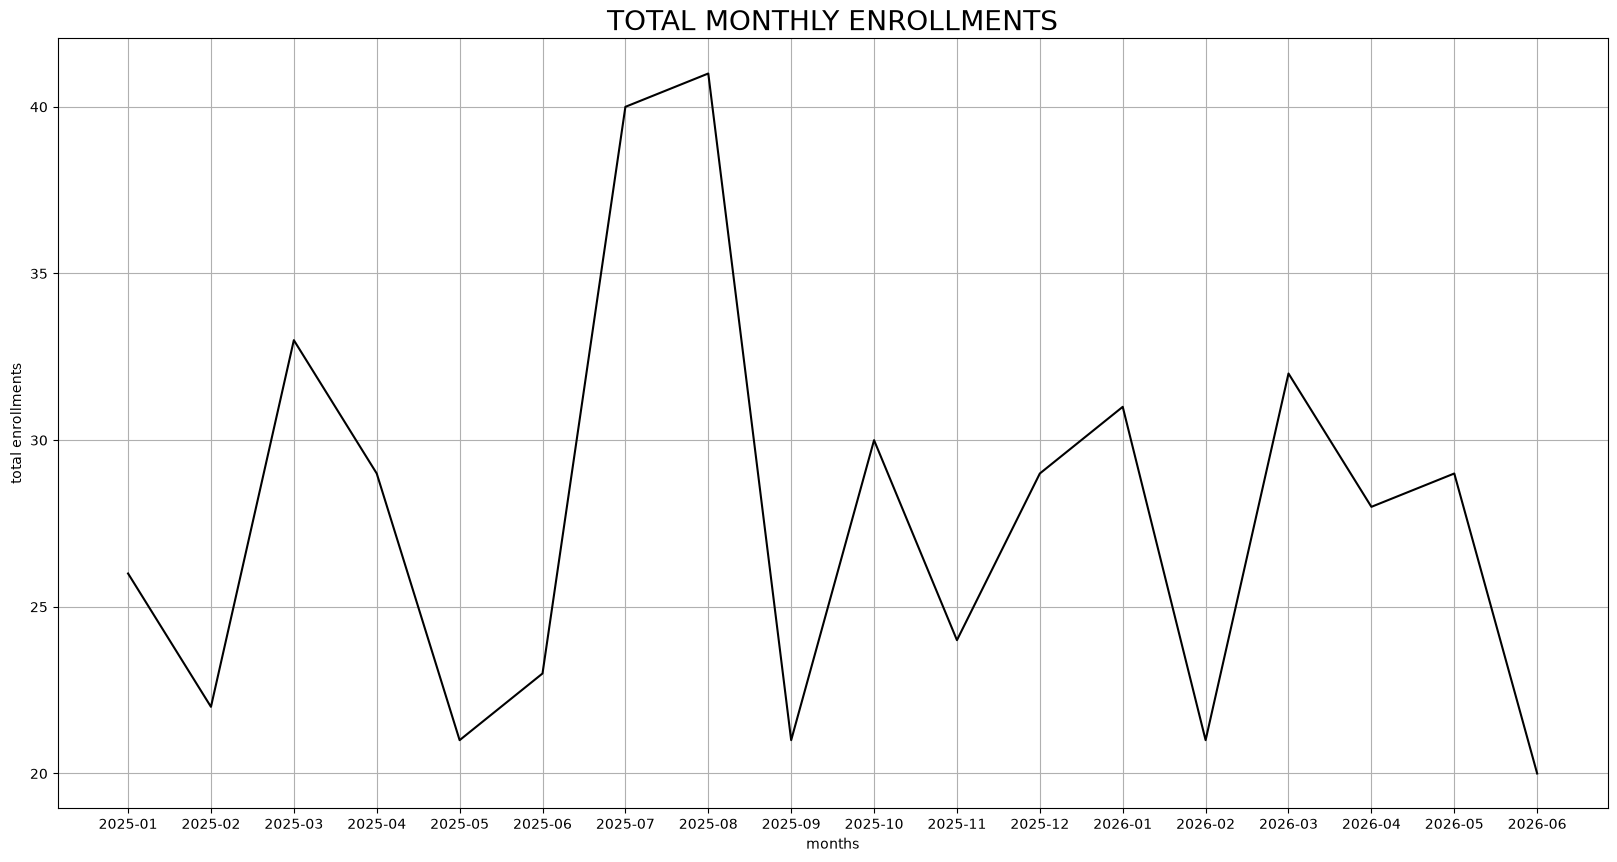

In [68]:
#1.1 monthly student enrollments
# this qn alone took me 48minutes to understand and solve but i got it finally
dd["EnrollmentDate"] = pd.to_datetime(dd["EnrollmentDate"]) # convert date str value to datetime # yo hamile padethenam from lectures
#dd["EnrollmentDate"]
dd["Month"] = dd["EnrollmentDate"].dt.to_period("M") # month ma convert garem 2025-1
# new syntax for me but didnot used .dt.month because different year pani xa
monthly_enroll = dd.groupby(dd['Month']).size() # group garem each similar value ra count garem
#monthly_enroll #la thik xa balla right 
plt.figure(figsize=(20,10)) # saguro bhayo
monthly_enroll.index= monthly_enroll.index.astype(str) # it didnot ran becuase yo ma chai plot garda float ma convert garna khojyo but it cannot convert so str banako
plt.plot(monthly_enroll.index,monthly_enroll.values,color='black') # this is normal
plt.xlabel('months',fontsize = 10)
plt.ylabel('total enrollments',fontsize= 10)
plt.title('TOTAL MONTHLY ENROLLMENTS',fontsize= 20)
plt.grid()

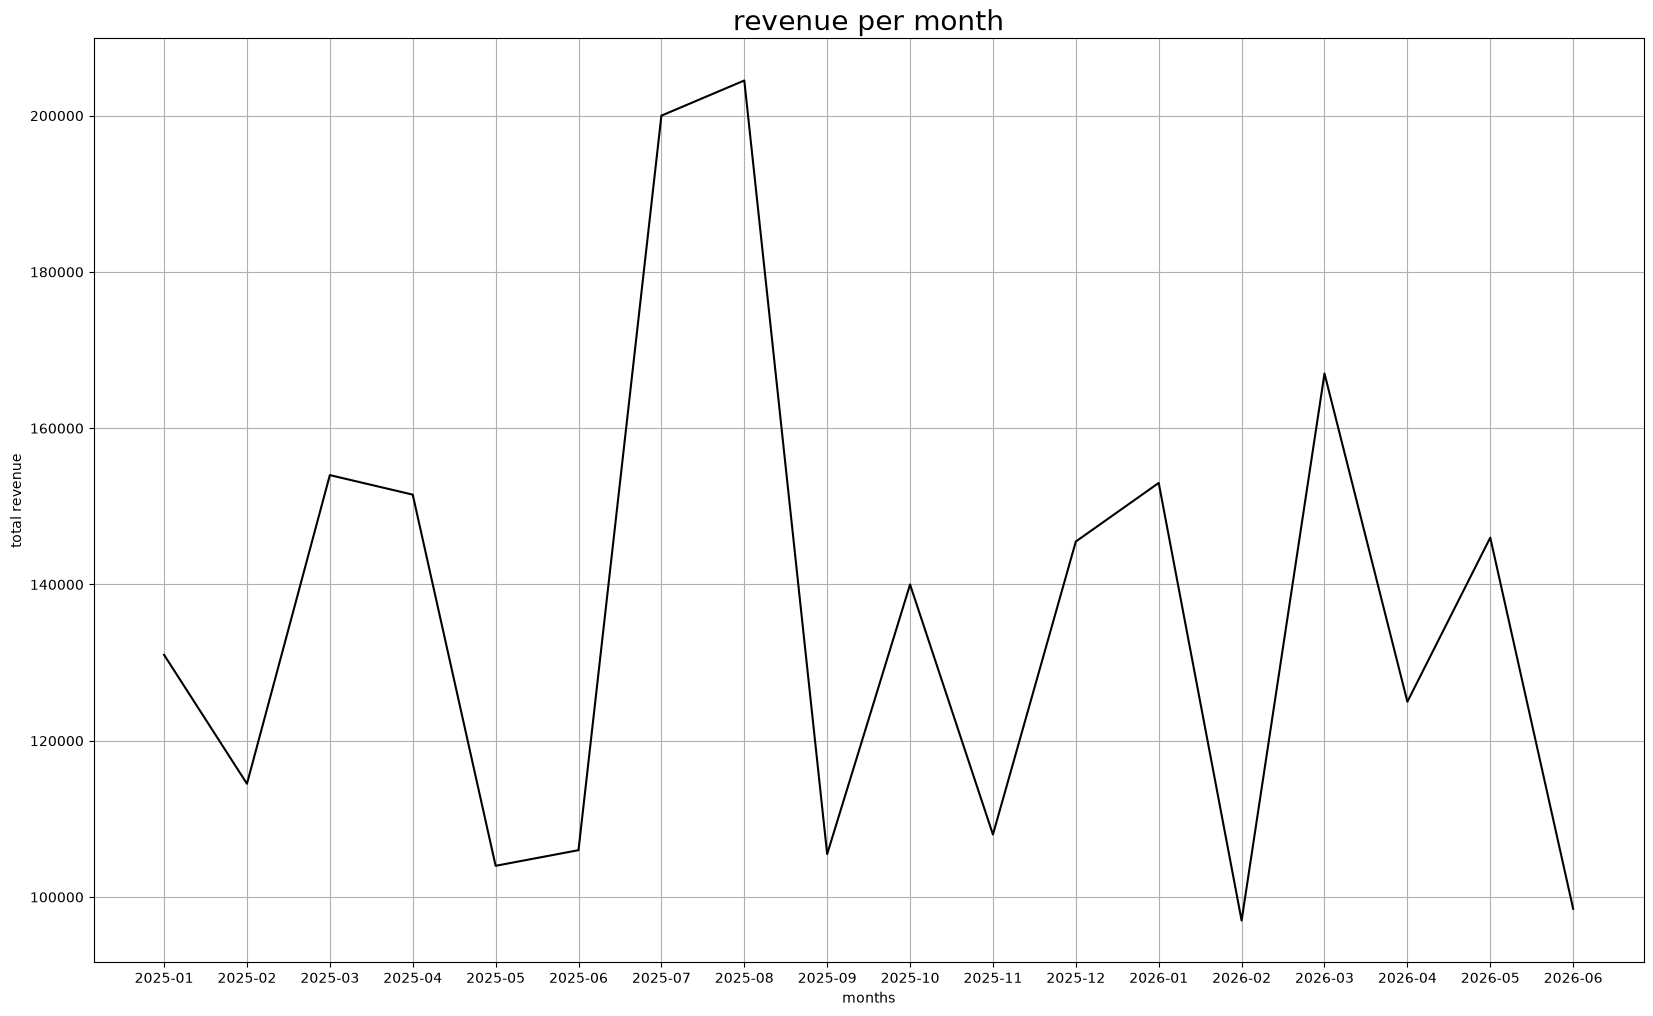

In [75]:
# 1.2monthly revenue trend  # same to same 
revenue=dd.groupby('Month')['Revenue'].sum()
plt.figure(figsize=(20,12))
plt.plot(revenue.index.astype(str),revenue.values,color='black')
plt.xlabel('months',fontsize = 10)
plt.ylabel('total revenue',fontsize= 10)
plt.title('revenue per month',fontsize= 20)
plt.grid()

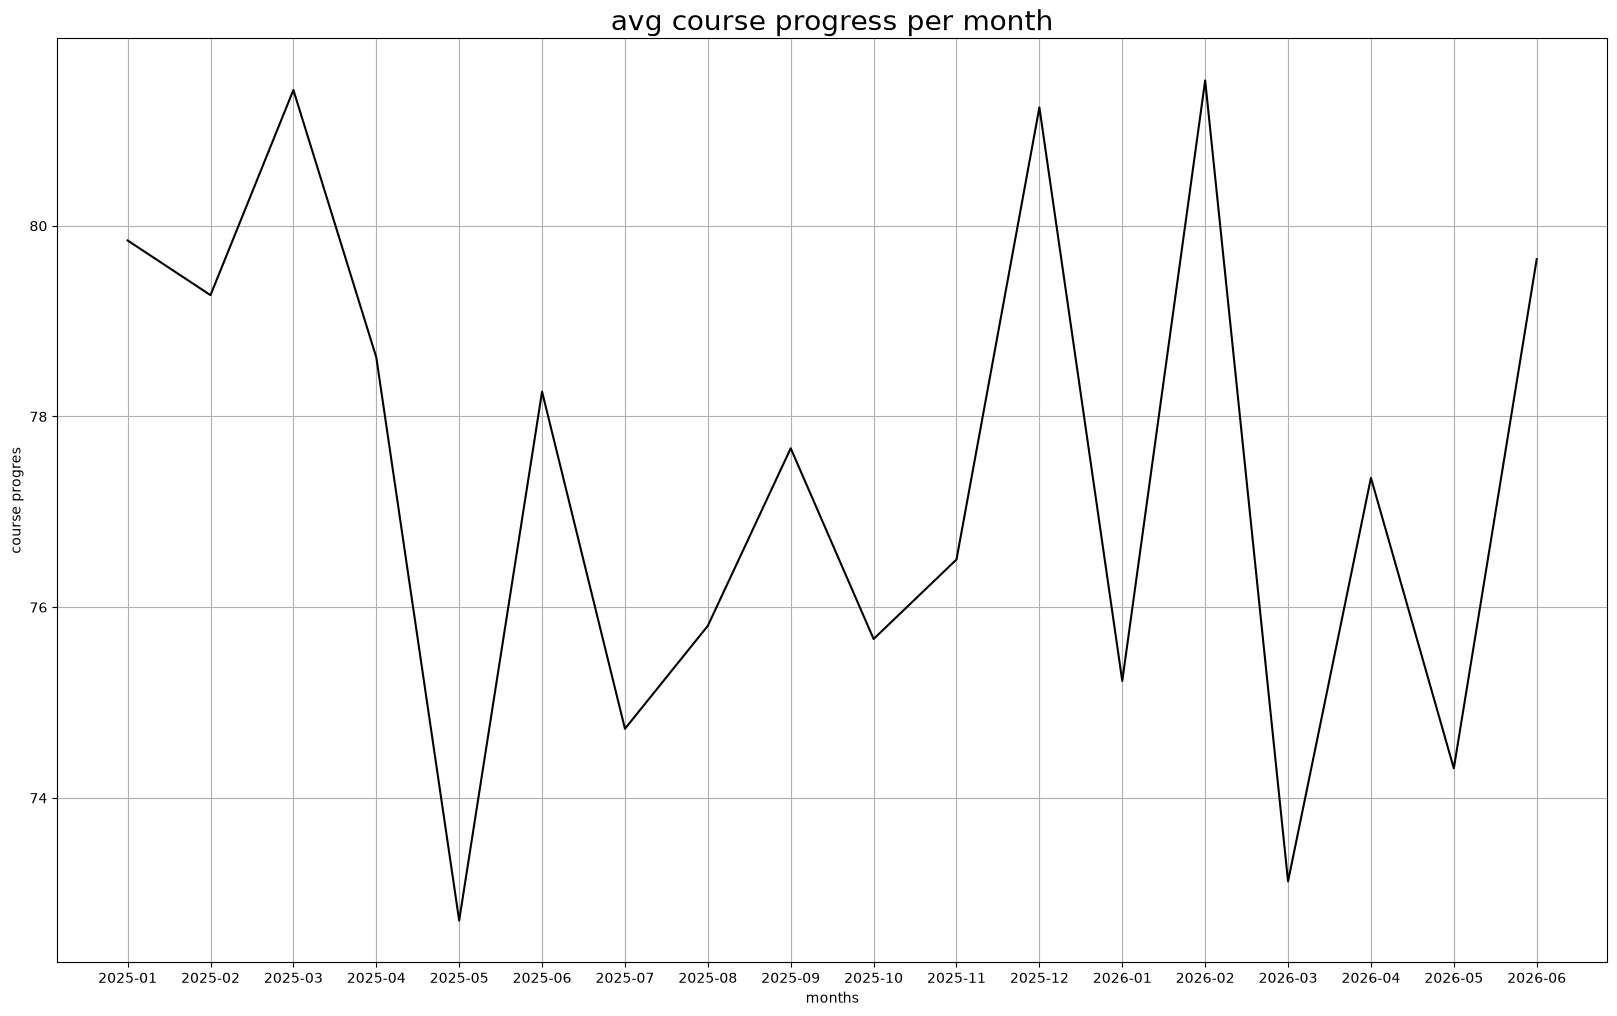

In [74]:
# 1.3 average course progress  by month
avg_progress = dd.groupby('Month')['CourseProgress'].mean()
plt.figure(figsize=(20,12))
avg_progress
plt.plot(avg_progress.index.astype(str),avg_progress.values,color='black')
plt.xlabel('months',fontsize = 10)
plt.ylabel('course progres',fontsize= 10)
plt.title('avg course progress per month',fontsize= 20)
plt.grid()

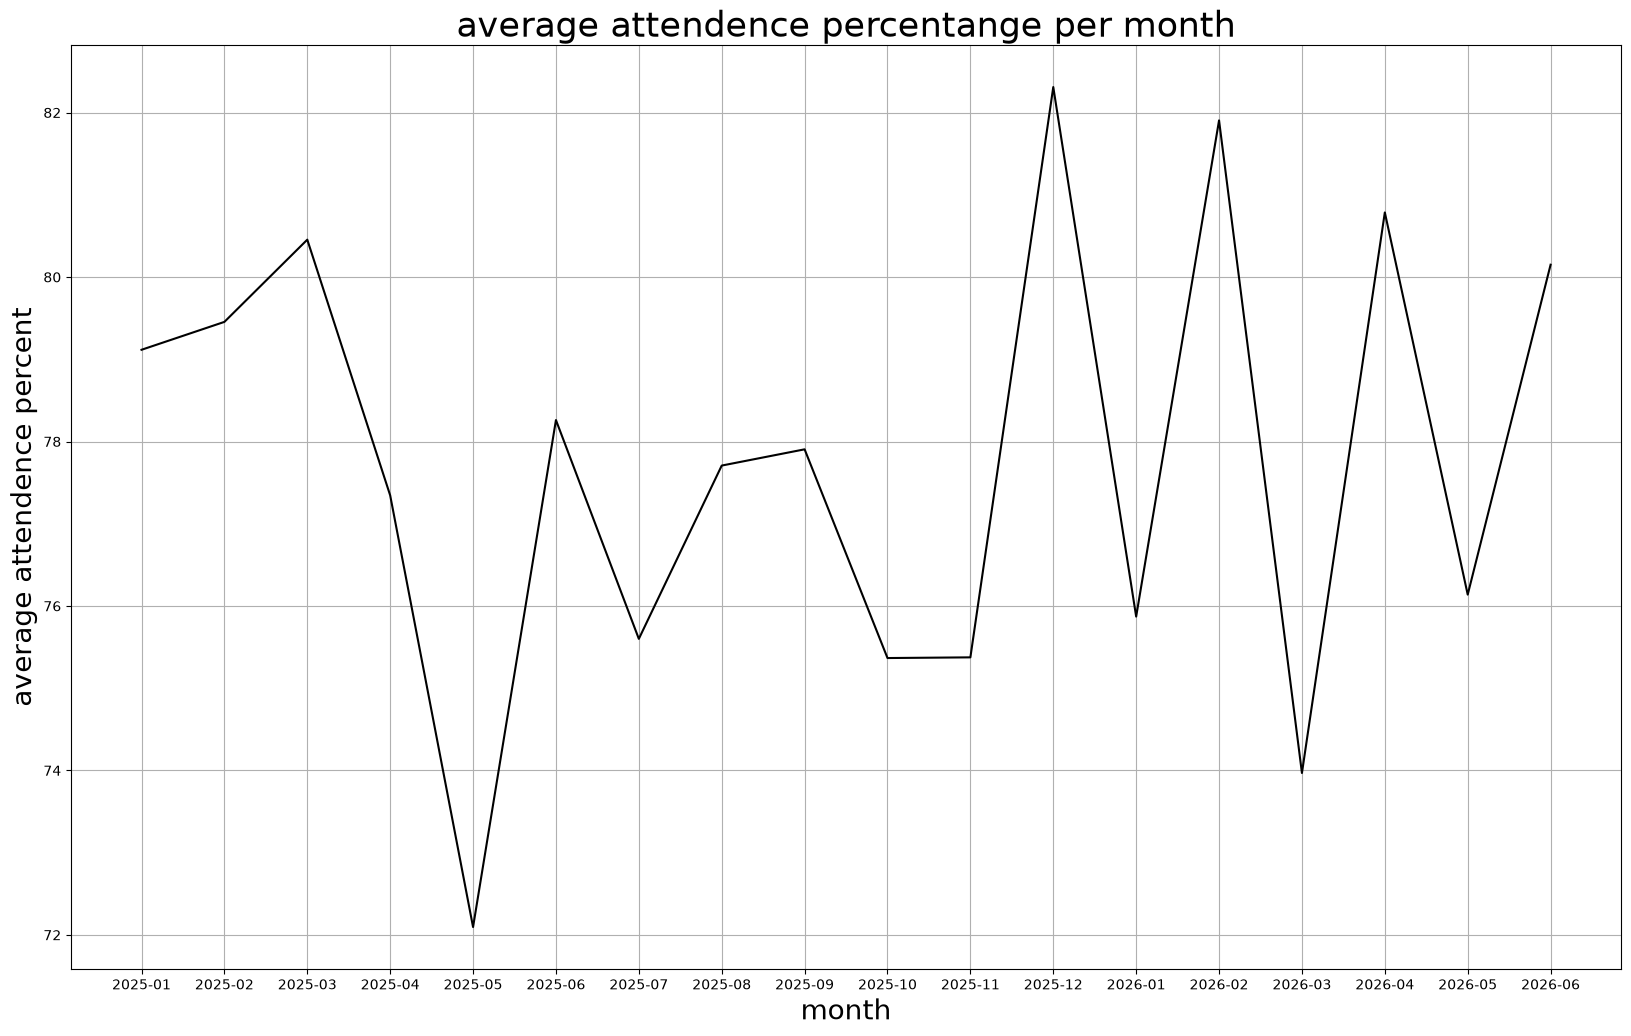

In [82]:
#1.4 average attendence percentange per month
avg_attendance =dd.groupby('Month')['AttendancePercentage'].mean()
plt.figure(figsize=(20,12))
plt.plot(avg_attendance.index.astype(str),avg_attendance.values,color='black')
plt.ylabel('average attendence percent',fontsize=20)
plt.xlabel('month',fontsize=20)
plt.title('average attendence percentange per month',fontsize=25)
plt.grid()

In [83]:
#2 bar charts

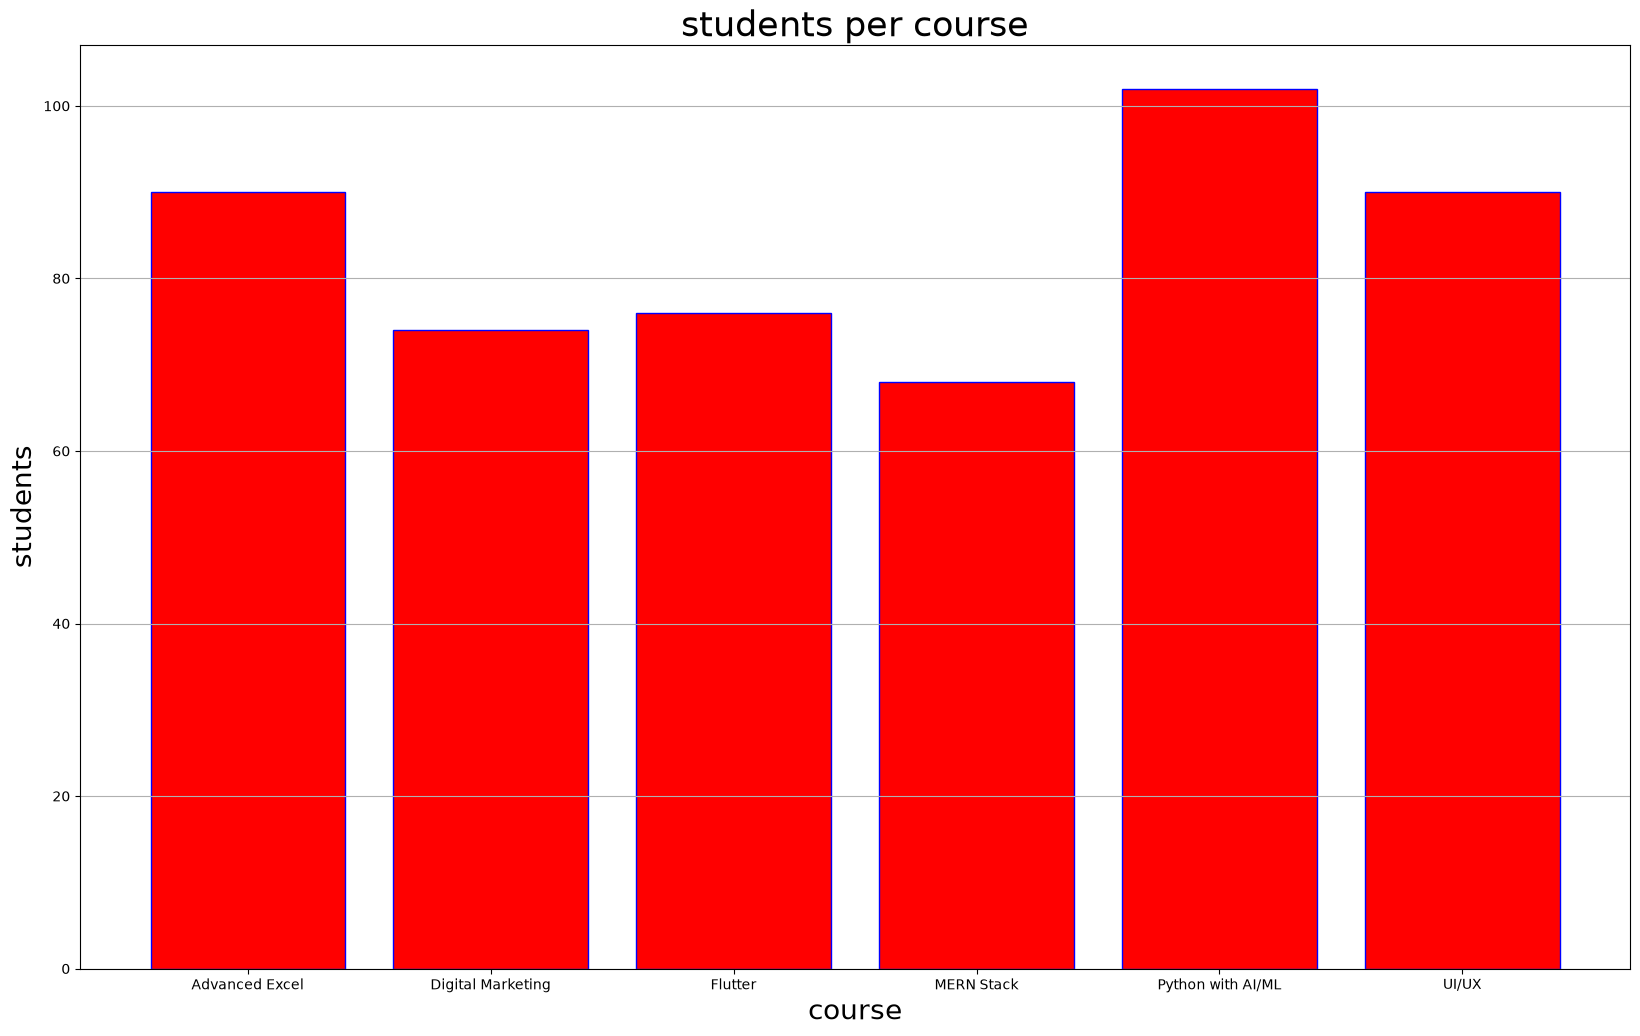

In [129]:
#2.1students per course

plt.figure(figsize=(20,12))
student_course=dd.groupby('Course')['StudentName'].count()

plt.bar(student_course.index,student_course.values,color='red',edgecolor='blue')

plt.ylabel('students',fontsize=20)
plt.xlabel('course',fontsize=20)
plt.title('students per course',fontsize=25)
plt.grid(axis='y')


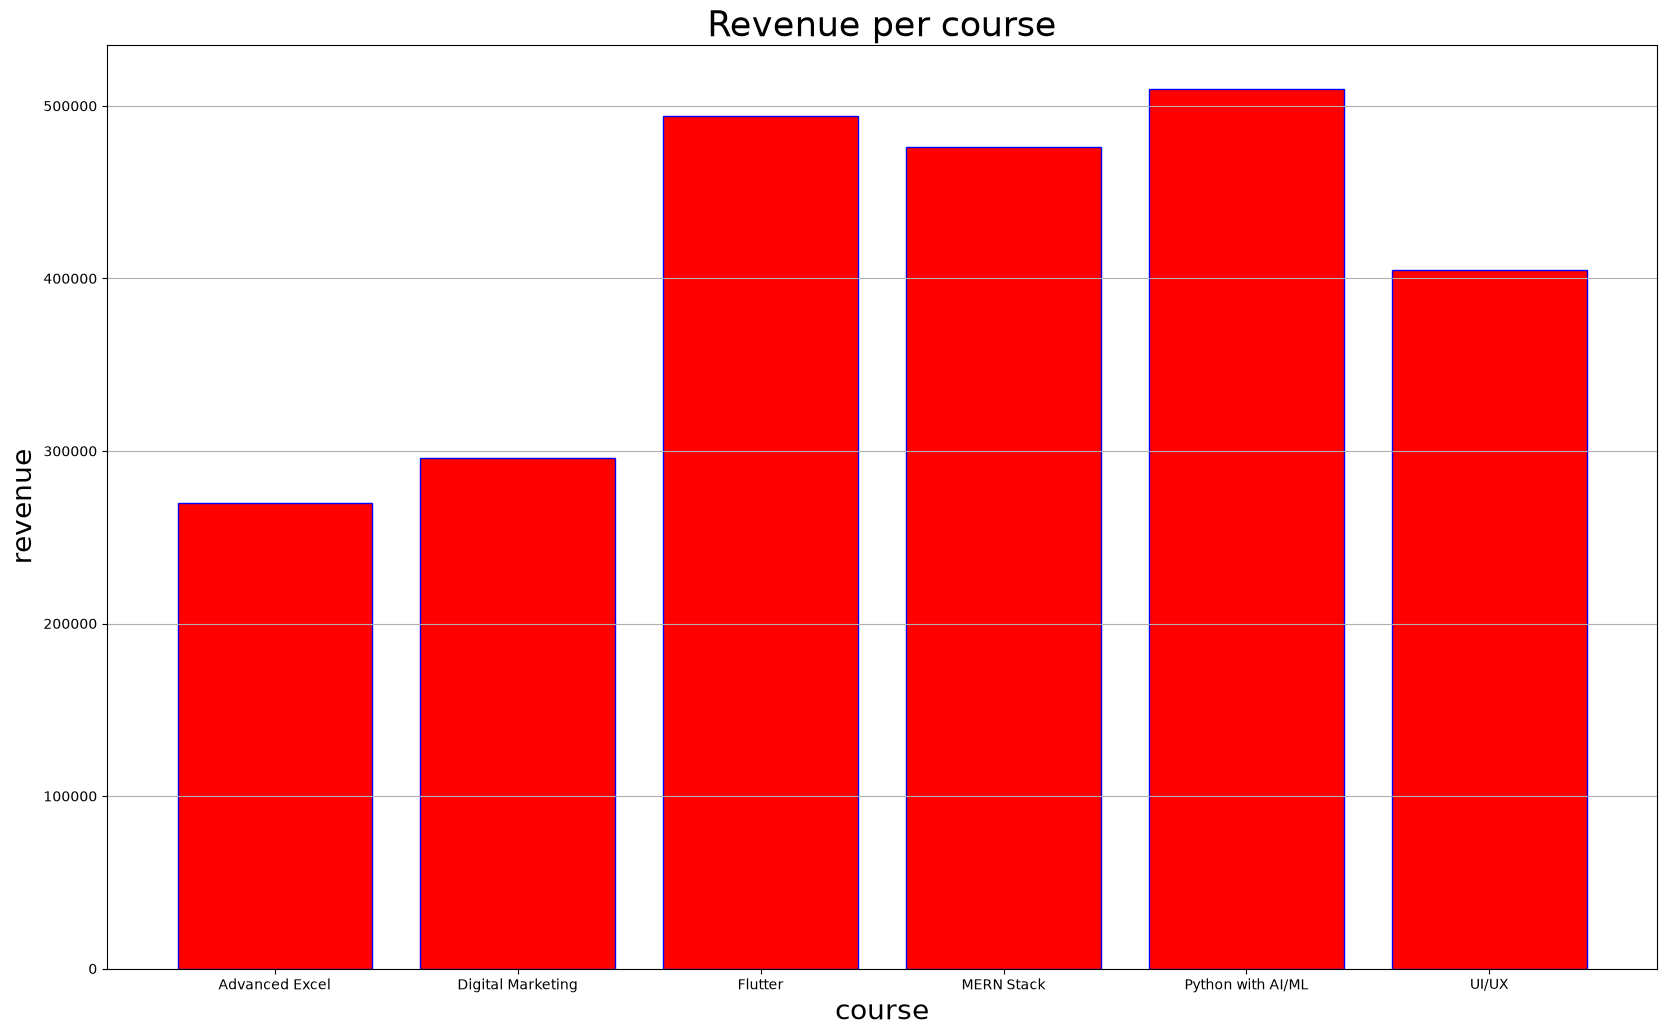

In [102]:
#2.2 revenue generated per each course
plt.figure(figsize=(20,12))
revenue=dd.groupby('Course')['Revenue'].sum()
plt.bar(revenue.index,revenue.values,color='red',edgecolor='blue')
plt.ylabel('revenue',fontsize=20)
plt.xlabel('course',fontsize=20)
plt.title('Revenue per course',fontsize=25)
plt.grid(axis='y')

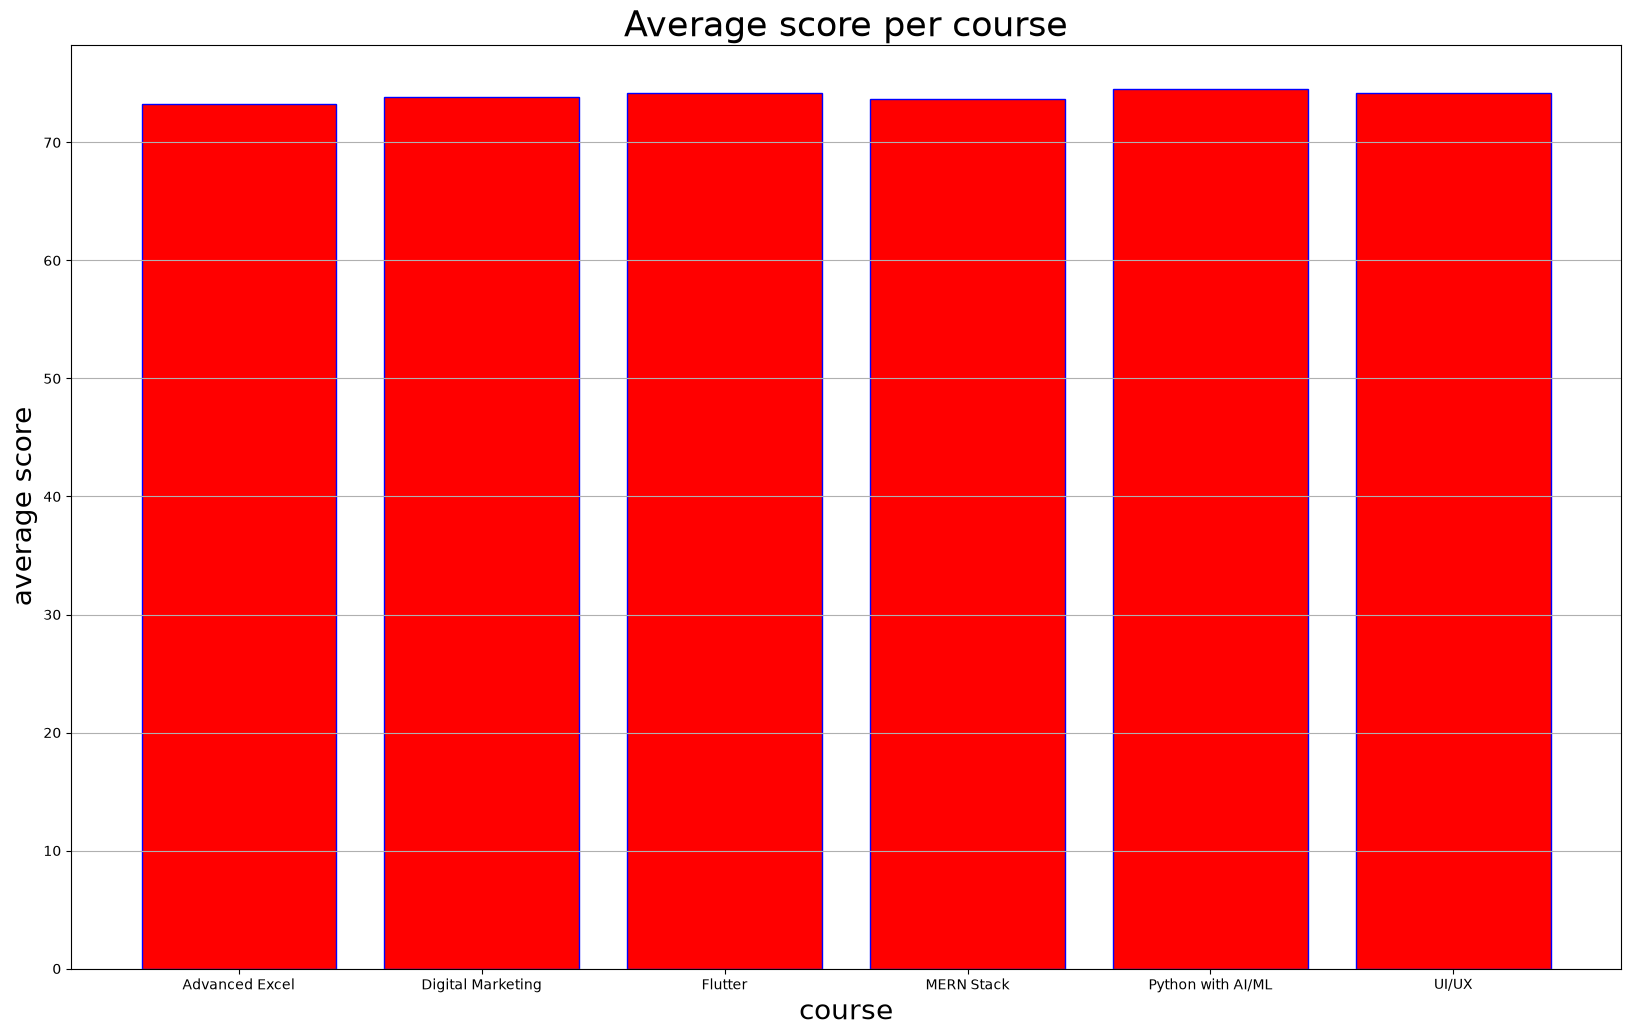

In [109]:
#2.3 average final score by course
plt.figure(figsize=(20,12))
final_score=dd.groupby('Course')['FinalScore'].mean()
plt.bar(final_score.index,final_score.values,color='red',edgecolor='blue')
plt.ylabel('average score',fontsize=20)
plt.xlabel('course',fontsize=20)
plt.title('Average score per course',fontsize=25)
plt.grid(axis='y')

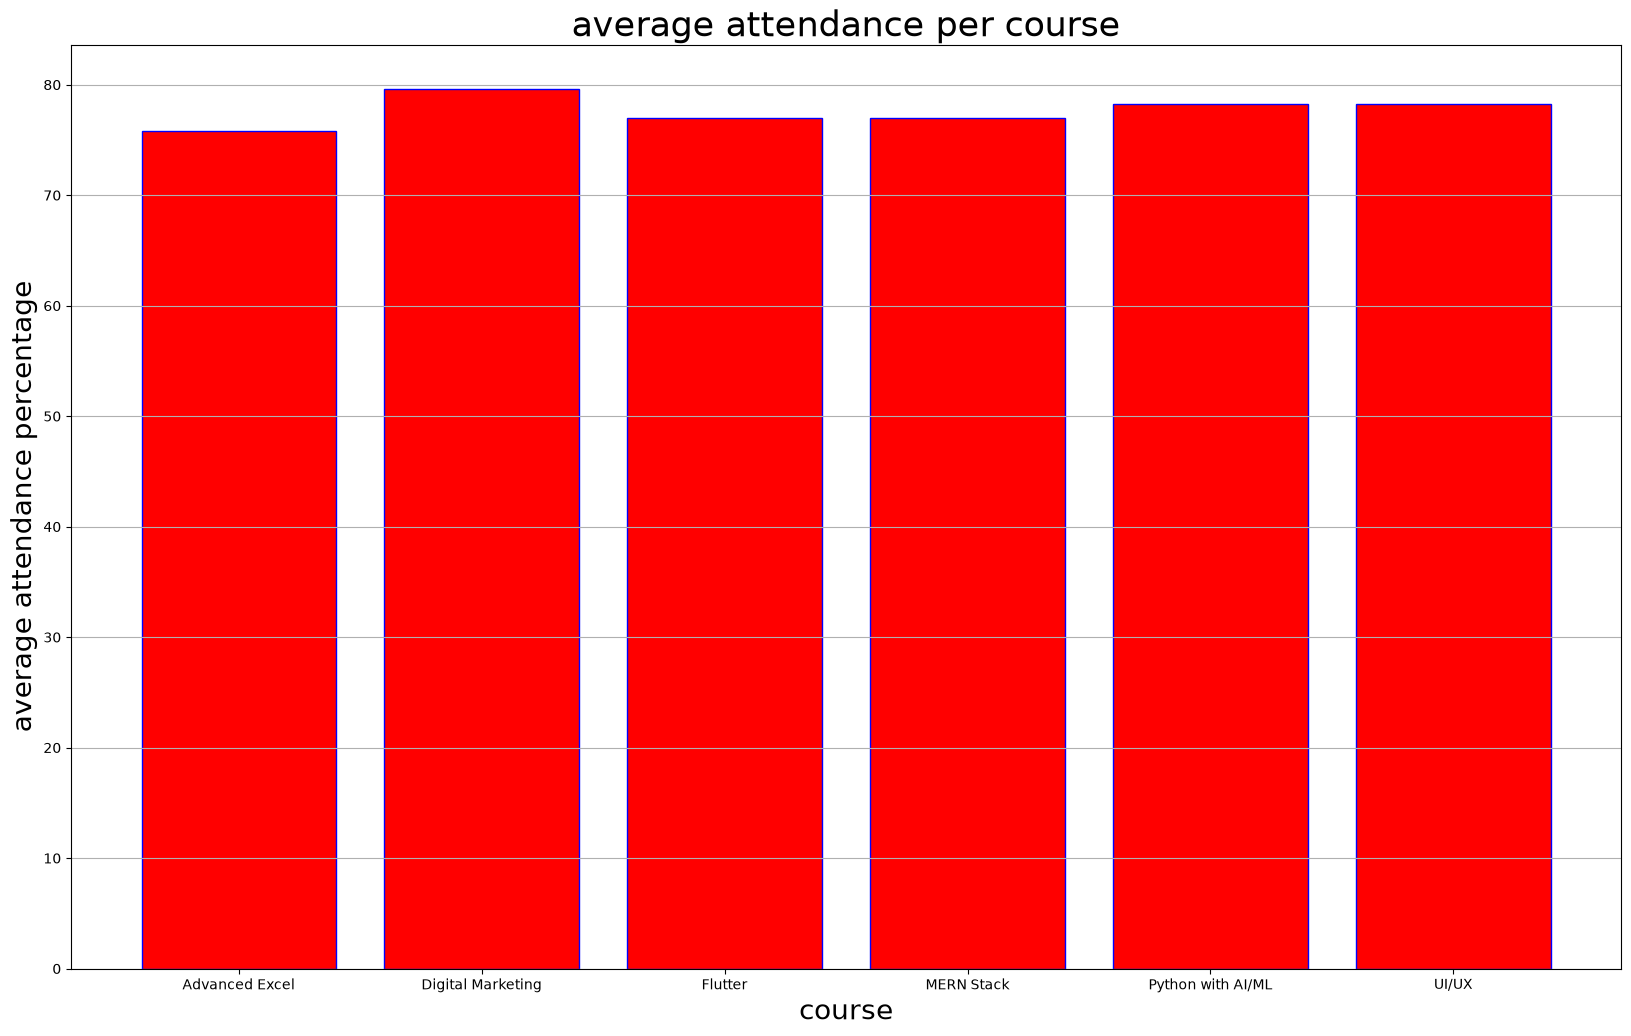

In [112]:
#2.4 average attendence percentage per course
plt.figure(figsize=(20,12))
avg_attendance=dd.groupby('Course')['AttendancePercentage'].mean()
plt.bar(avg_attendance.index,avg_attendance.values,color='red',edgecolor='blue')
plt.ylabel('average attendance percentage',fontsize=20)
plt.xlabel('course',fontsize=20)
plt.title('average attendance per course',fontsize=25)
plt.grid(axis='y')

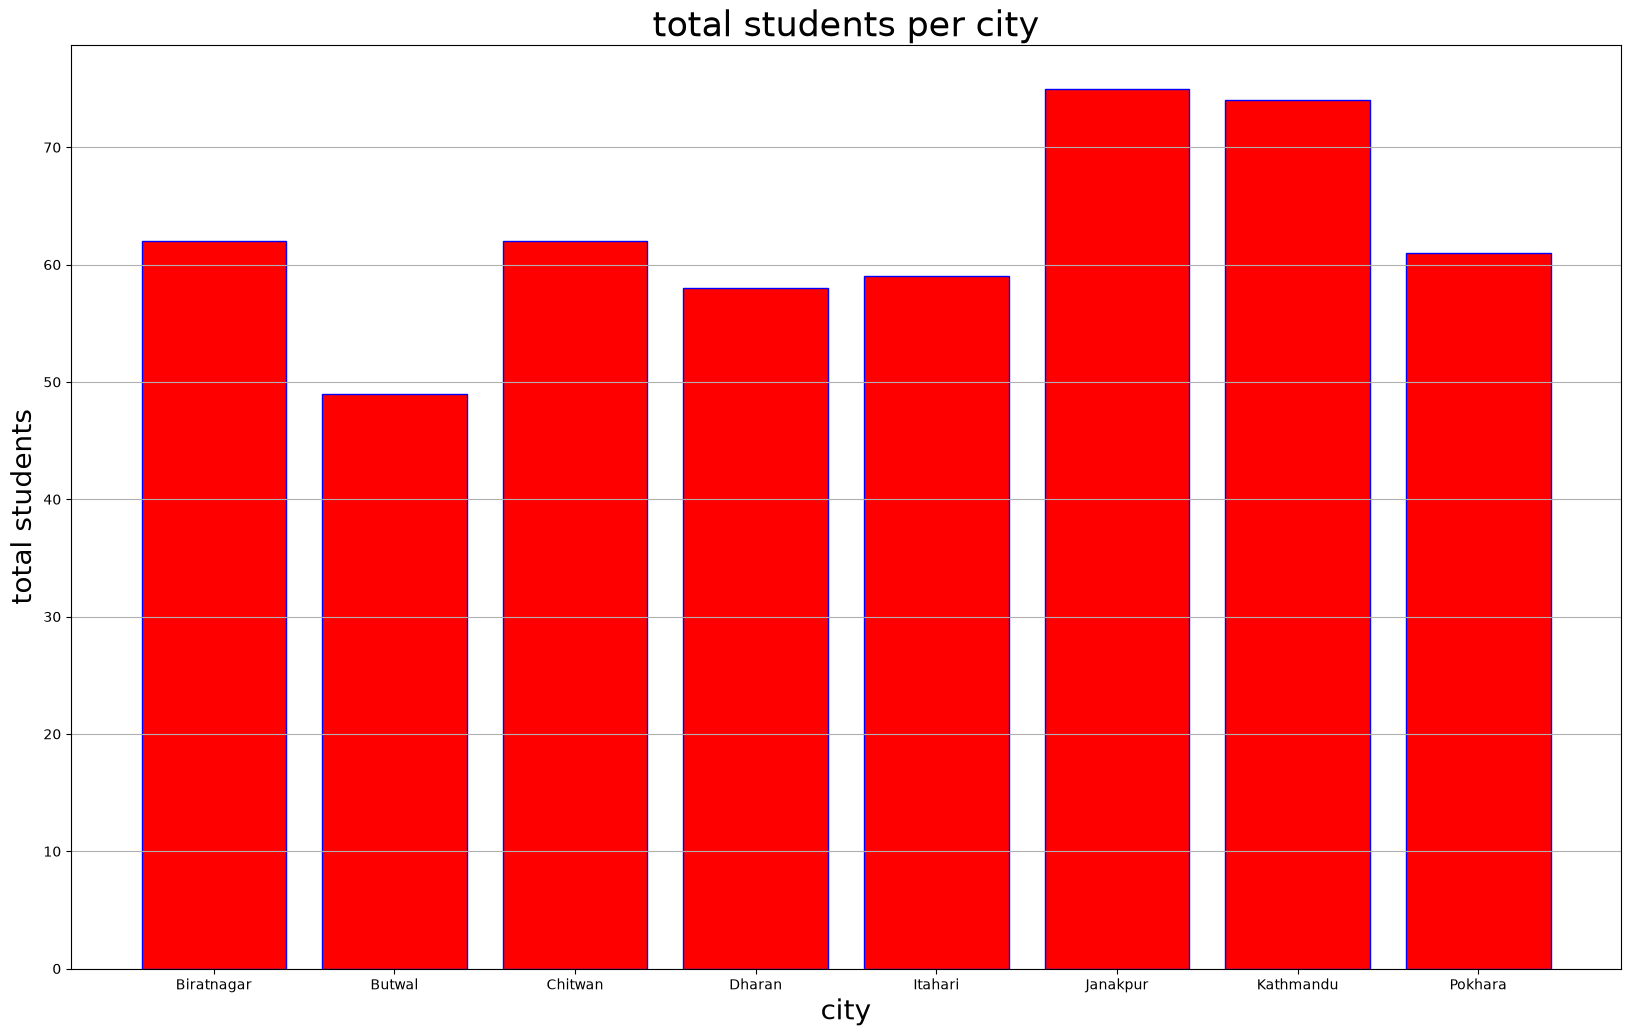

In [119]:
#2.5 number of students from each city
student=dd.groupby('City')['StudentName'].count()
plt.figure(figsize=(20,12))
plt.bar(student.index,student.values,color='red',edgecolor='blue')
plt.ylabel('total students',fontsize=20)
plt.xlabel('city',fontsize=20)
plt.title('total students per city',fontsize=25)
plt.grid(axis='y')

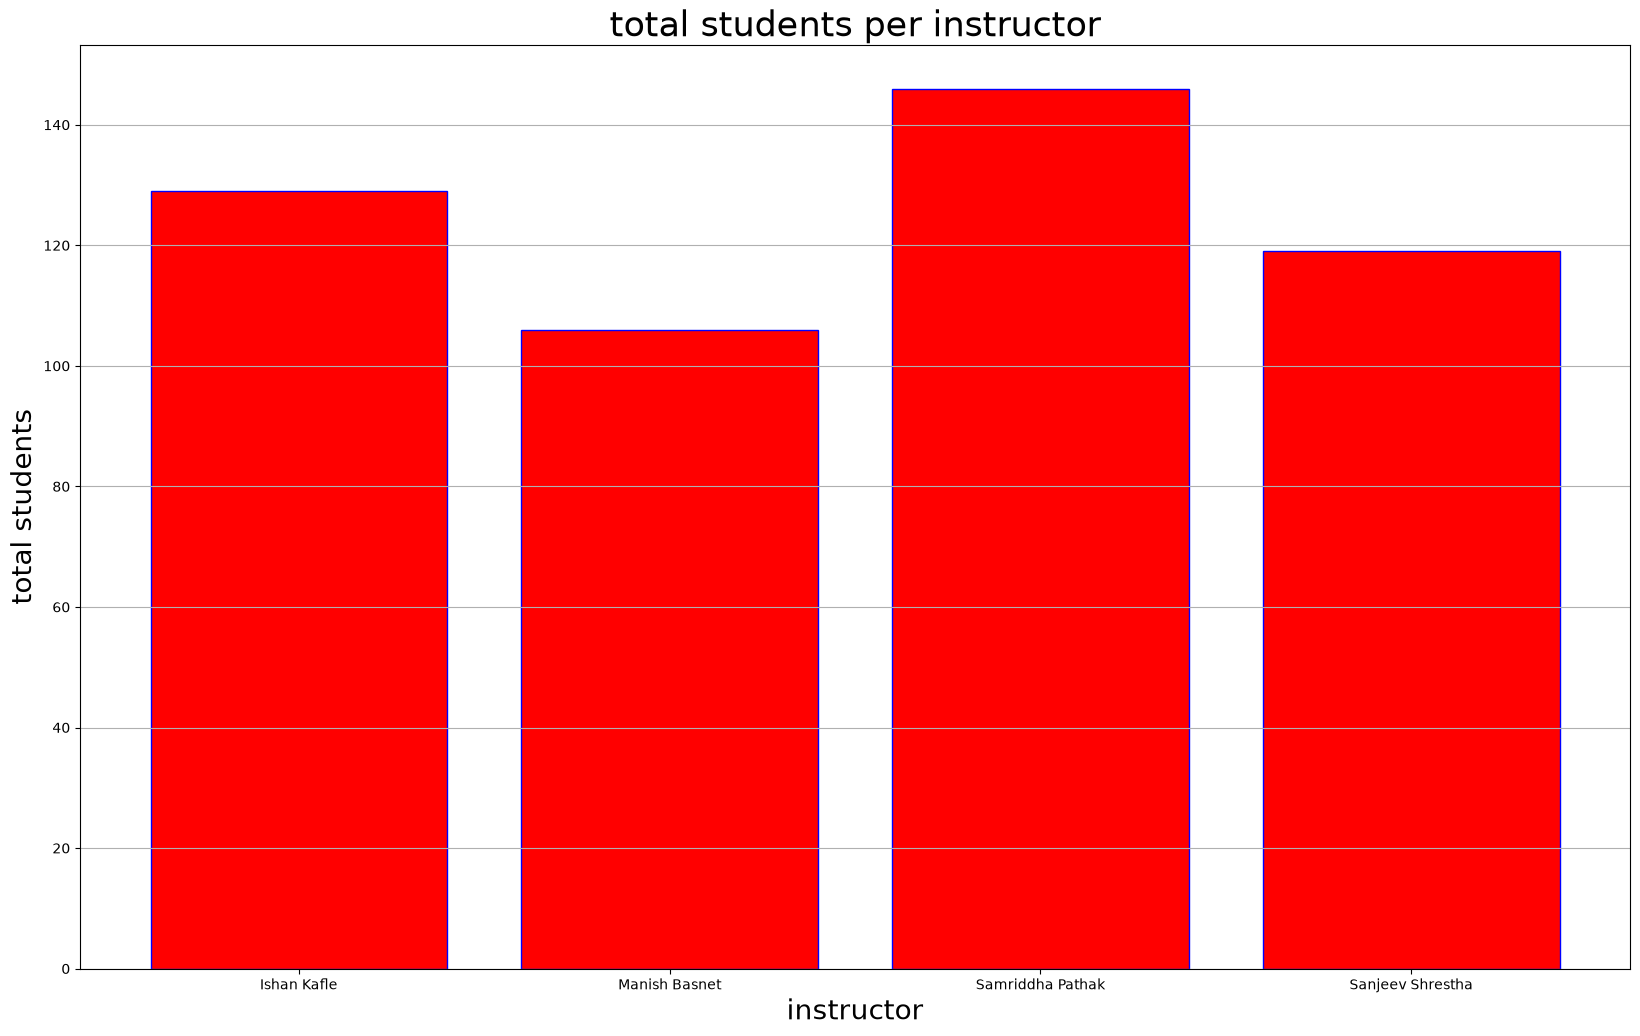

In [134]:
#2.6 number of students under each instructor
students=dd.groupby('Instructor')['StudentName'].count()
plt.figure(figsize=(20,12))
plt.bar(students.index,students.values,color='red',edgecolor='blue')
plt.ylabel('total students',fontsize=20)
plt.xlabel('instructor',fontsize=20)
plt.title('total students per instructor',fontsize=25)
plt.grid(axis='y')

In [ ]:
#3 horizontal bar charts

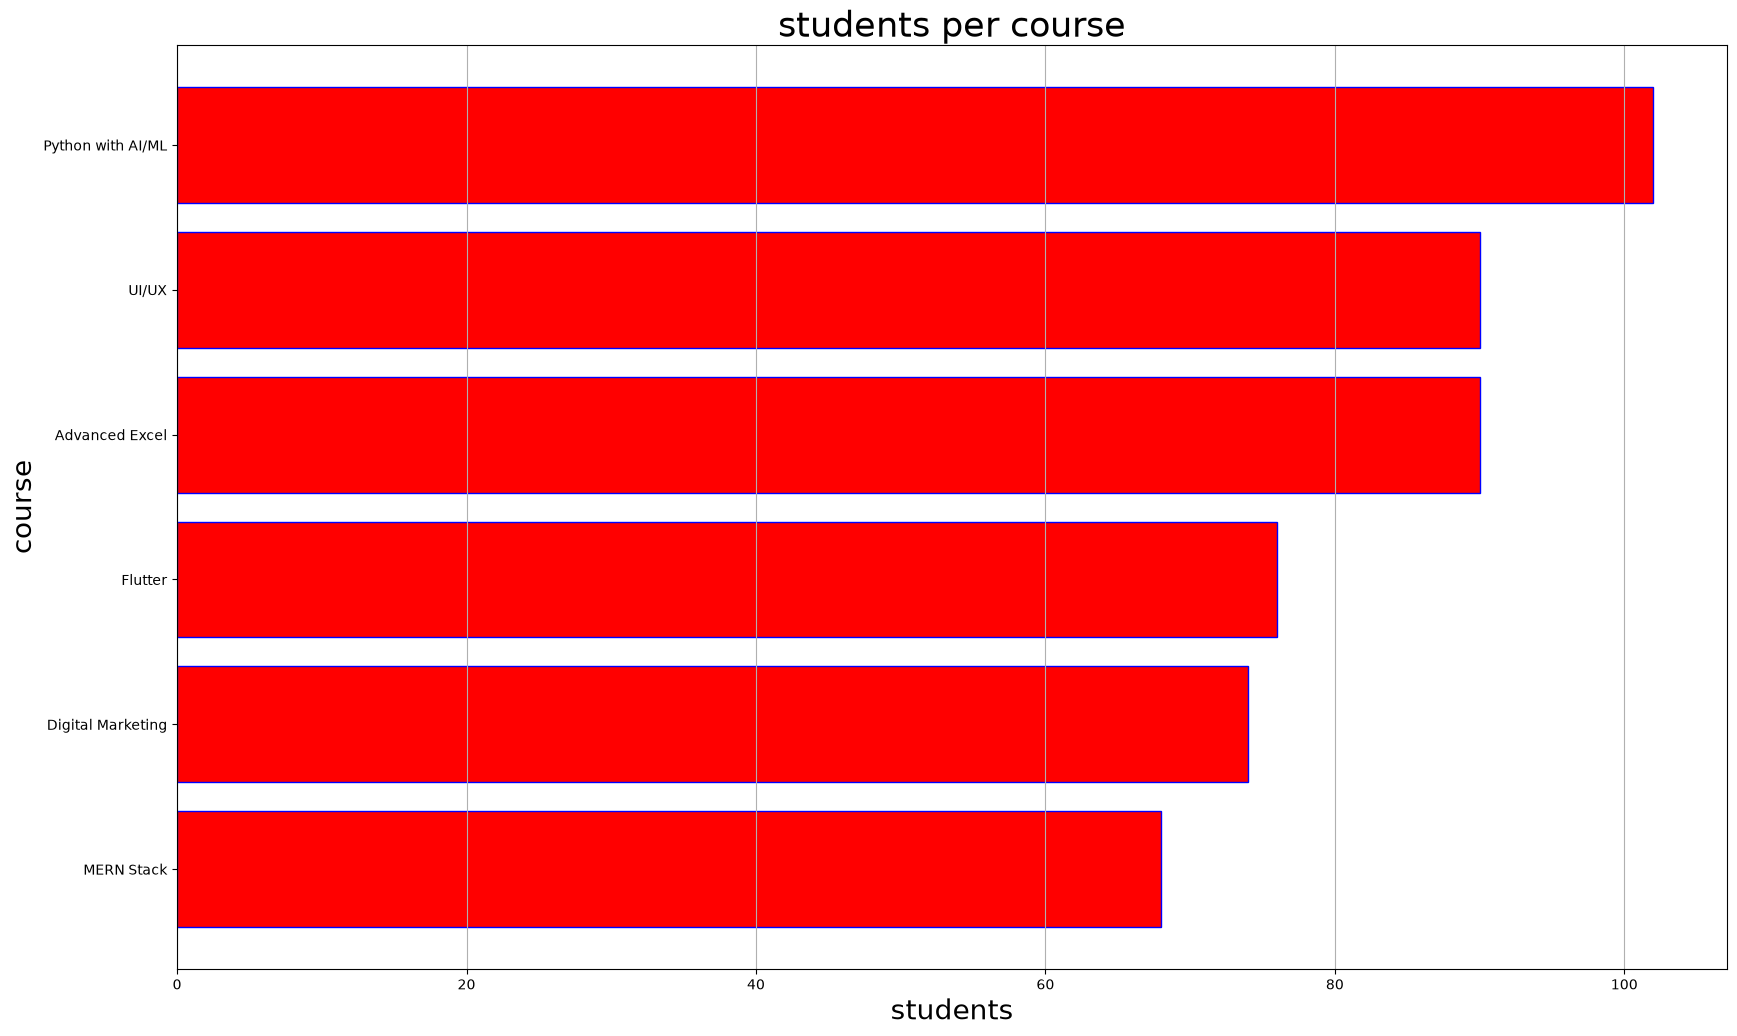

In [146]:
#3.1 top 10 courses by enrollments
# something that we didnot read in courses
#dd['Course'].unique()  only 6 ota course xa so all goes to top 10
student_course=dd.groupby('Course')['StudentName'].count().sort_values()
plt.figure(figsize=(20,12))
plt.barh(student_course.index,student_course.values,color='red',edgecolor='blue')
plt.ylabel('course',fontsize=20)
plt.xlabel('students',fontsize=20)
plt.title('students per course',fontsize=25)
plt.grid(axis='x')

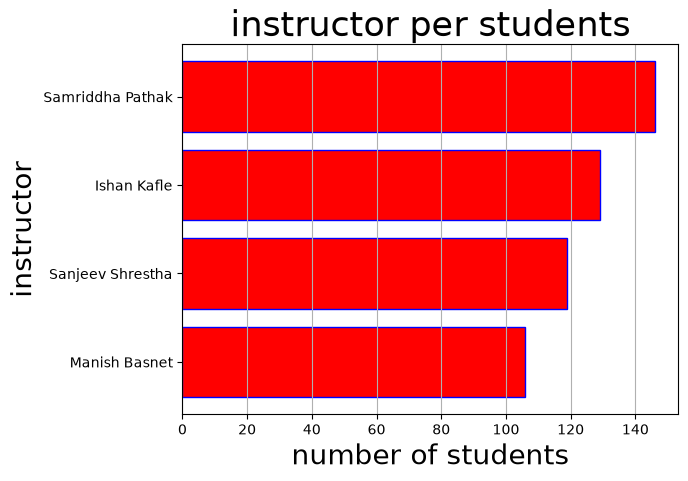

In [147]:
# 3.2 top 10 instructor by student enrollments
instructor=dd.groupby('Instructor')['StudentName'].count().sort_values()
plt.barh(instructor.index,instructor.values,color='red',edgecolor='blue')
plt.ylabel('instructor',fontsize=20)
plt.xlabel('number of students',fontsize=20)
plt.title('instructor per students',fontsize=25)
plt.grid(axis='x')

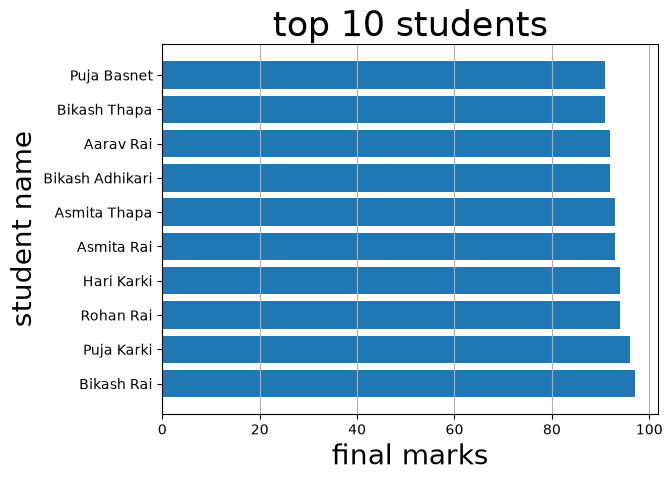

In [167]:
#3.3 top 10 students with the highest final scores
# little different question than above
top10 = dd.sort_values('FinalScore',ascending=False).head(10)
plt.barh(top10['StudentName'],top10['FinalScore'])
plt.ylabel('student name',fontsize=20)
plt.xlabel('final marks',fontsize=20)
plt.title('top 10 students',fontsize=25)
plt.grid(axis='x')

In [168]:
#4 histograms

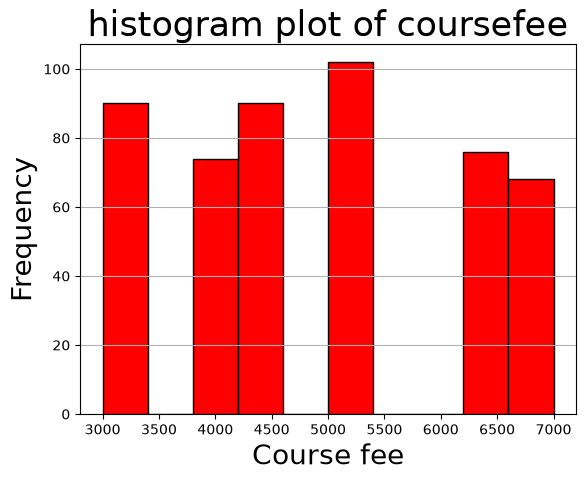

In [179]:
#4.1 histogram for course fee
plt.hist(dd['CourseFee'],color='red',edgecolor='black')
plt.ylabel('Frequency',fontsize=20)
plt.xlabel('Course fee',fontsize=20)
plt.title('histogram plot of coursefee',fontsize=25)
plt.grid(axis='y')

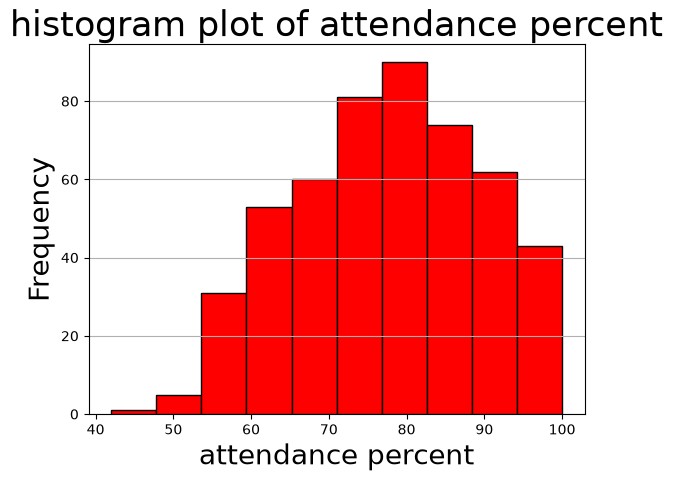

In [180]:
#4.2 attendance percent
plt.hist(dd['AttendancePercentage'],color='red',edgecolor='black')
plt.ylabel('Frequency',fontsize=20)
plt.xlabel('attendance percent',fontsize=20)
plt.title('histogram plot of attendance percent',fontsize=25)
plt.grid(axis='y')

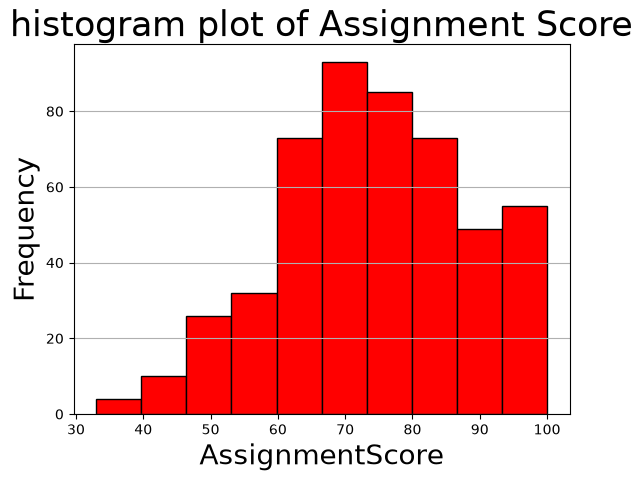

In [181]:
#4.3 assignment score
plt.hist(dd['AssignmentScore'],color='red',edgecolor='black')
plt.ylabel('Frequency',fontsize=20)
plt.xlabel('AssignmentScore',fontsize=20)
plt.title('histogram plot of Assignment Score',fontsize=25)
plt.grid(axis='y')

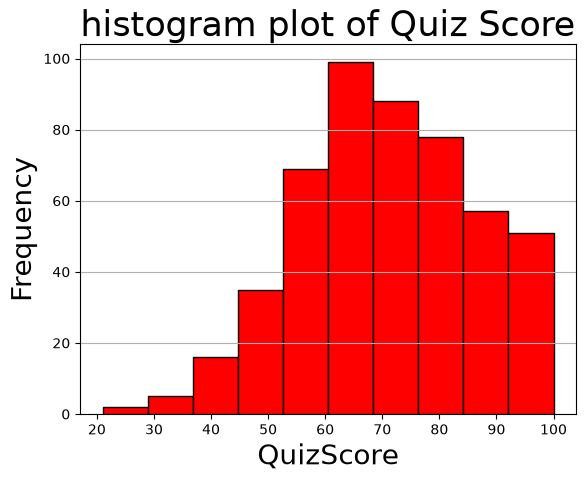

In [182]:
#4.3 quiz score
plt.hist(dd['QuizScore'],color='red',edgecolor='black')
plt.ylabel('Frequency',fontsize=20)
plt.xlabel('QuizScore',fontsize=20)
plt.title('histogram plot of Quiz Score',fontsize=25)
plt.grid(axis='y')

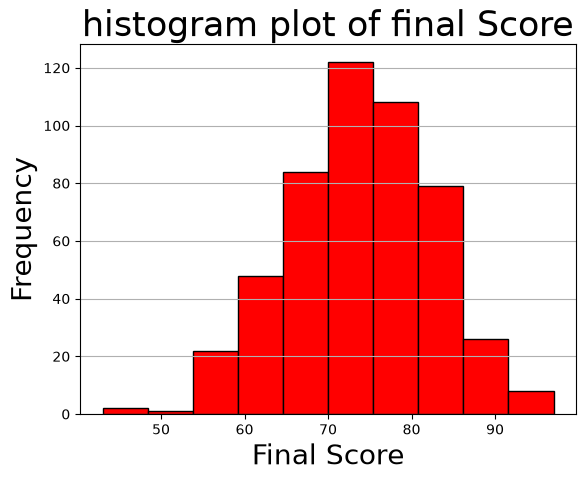

In [183]:
#4.3 Final score
plt.hist(dd['FinalScore'],color='red',edgecolor='black')
plt.ylabel('Frequency',fontsize=20)
plt.xlabel('Final Score',fontsize=20)
plt.title('histogram plot of final Score',fontsize=25)
plt.grid(axis='y')

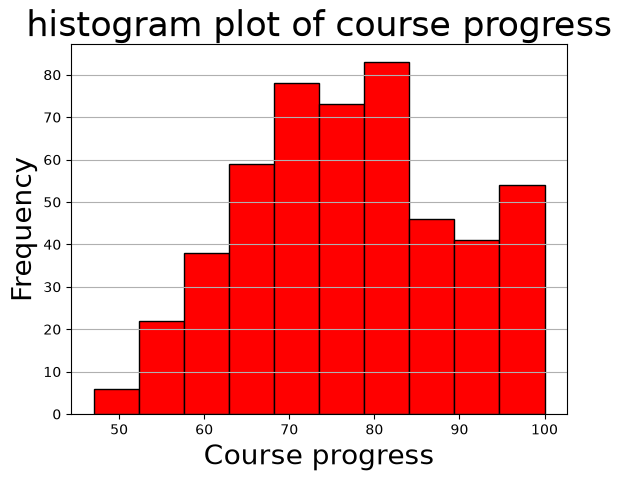

In [184]:
#4.3 course progress
plt.hist(dd['CourseProgress'],color='red',edgecolor='black')
plt.ylabel('Frequency',fontsize=20)
plt.xlabel('Course progress',fontsize=20)
plt.title('histogram plot of course progress',fontsize=25)
plt.grid(axis='y')

In [185]:
#5pie charts
